## Data layout

This notebook is part of the Figshare item `cellpose-SAM-training`. Download the whole item,
unzip every zip in place and run the notebook from that folder; all paths are relative to it:

```
cellpose-SAM-training/
    basement_membrane_training.ipynb
    BM_model_benchmarking.ipynb
    SMG-BM-seg-training/      (from SMG-BM-seg-training.zip)
    train_manual/             (from train_manual.zip)
    BM-seg-benchmarking/      (from BM-seg-benchmarking.zip)
    BM-img-to-test/           (from BM-img-to-test.zip)
    models/                   (written by training; or put the downloaded SMG-BM-v0907 /
                               SMG-BM-15V files here to skip training)
```

Cellpose saves trained models to `models/<model_name>`; figures go to `jupyter_figures/`.
See `README.md` for details. Paths were changed from the original
working copy only; the code is otherwise unchanged.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from natsort import natsorted
from pathlib import Path

# for segmentation
from cellpose import io, transforms, models, utils
io.logger_setup()



Welcome to CellposeSAM, cellpose v
cellpose version: 	4.0.4 
platform:       	win32 
python version: 	3.12.11 
torch version:  	2.7.1+cu126! The neural network component of
CPSAM is much larger than in previous versions and CPU excution is slow. 
We encourage users to use GPU/MPS if available. 


2025-11-09 15:43:08,275 [INFO] WRITING LOG OUTPUT TO C:\Users\wangs6\.cellpose\run.log
2025-11-09 15:43:08,275 [INFO] 
cellpose version: 	4.0.4 
platform:       	win32 
python version: 	3.12.11 
torch version:  	2.7.1+cu126


(<Logger cellpose.io (INFO)>, WindowsPath('C:/Users/wangs6/.cellpose/run.log'))

In [ ]:
root = Path(f"SMG-BM-seg-training/")
img_files = natsorted(list(root.glob("*.tif")))
mask_files = [f for f in img_files if "mask" in str(f)]
img_files = [f for f in img_files if "mask" not in str(f)]

imgs = [io.imread(f) for f in img_files]
masks = [io.imread(f) for f in mask_files]

print(imgs[0].shape)

imgs = [np.stack((imgs[2*i : 2*i+2]), axis=-1) for i in range(len(imgs)//2)]
imgs = [transforms.normalize_img(img, axis=-1) for img in imgs]

2025-11-09 15:43:08,342 [INFO] reading tiff with 166 planes


100%|██████████| 166/166 [00:00<00:00, 474.15it/s]

2025-11-09 15:43:08,712 [INFO] reading tiff with 166 planes



100%|██████████| 166/166 [00:00<00:00, 458.29it/s]

2025-11-09 15:43:09,090 [INFO] reading tiff with 166 planes


...

2025-11-09 15:43:23,438 [INFO] reading tiff with 166 planes


100%|██████████| 166/166 [00:00<00:00, 7467.10it/s]


2025-11-09 15:43:23,493 [INFO] reading tiff with 166 planes


100%|██████████| 166/166 [00:00<00:00, 5329.48it/s]

(166, 512, 512)


In [ ]:
img00 = [io.imread(f) for f in img_files[:2]]
img0 = [np.stack((img00[2*i : 2*i+2]), axis=-1) for i in range(len(img00)//2)]
img0_norm1 = [transforms.normalize_img(img, axis=-1) for img in img0]
img0_norm2 = [transforms.normalize_img(img, axis=-1, percentile=(0, 100)) for img in img0]

In [ ]:
len(img0)

In [ ]:
np.min(img0_norm1[0])

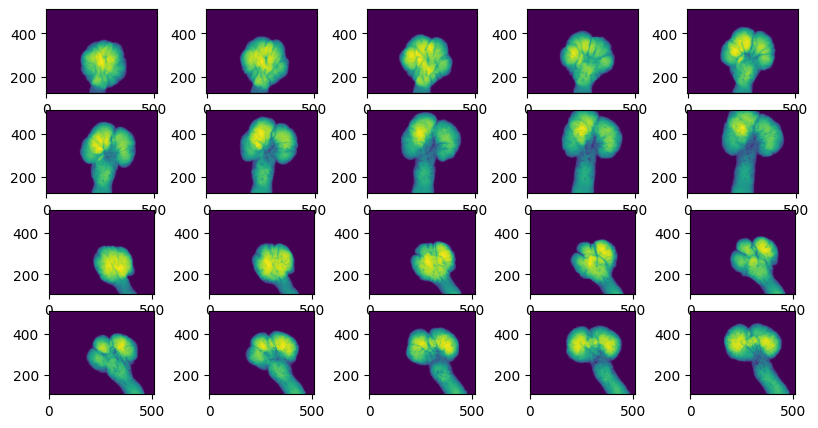

In [3]:
# Note, the crop setting is data specific.
# For this dataset, the algorithm-based segmentation ignored the base of the primary duct
crops = [124, 125, 105, 105]
fig, ax = plt.subplots(4, 5, figsize=(10, 5))
for i in range(len(masks)):
    ax[i // 5, i % 5].imshow(masks[i].sum(axis=0))
    ax[i // 5, i % 5].set_ylim([crops[i//5], masks[i].shape[1]])

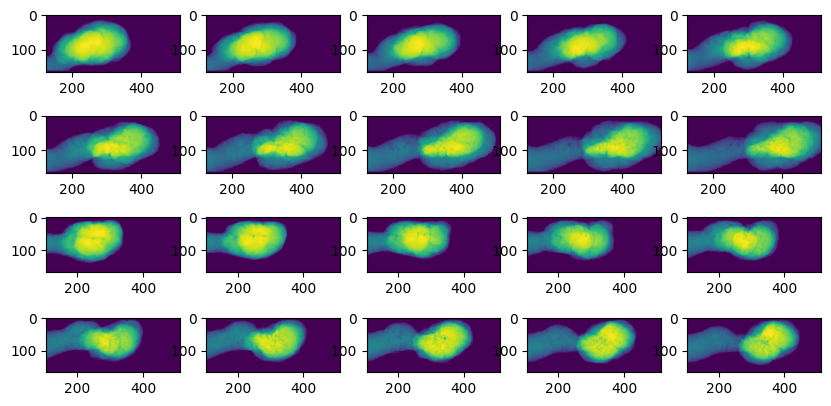

In [4]:
fig, ax = plt.subplots(4, 5, figsize=(10, 5))
for i in range(len(masks)):
    ax[i // 5, i % 5].imshow(masks[i].sum(axis=-1))
    ax[i // 5, i % 5].set_xlim([crops[i//5], masks[i].shape[1]])

### Train model with 15 annotated datasets

Extract 2D slices from 15 randomly selected annotated volumes

Keep the remaining volumes for benchmarking the model

In [ ]:
import random

# Create a range of numbers from 0 to 19
numbers = list(range(20))

# Select 15 random unique numbers
# NOTE: unseeded, so the split changes on every run. The split used for the
# recorded results and the saved masks in BM-seg-benchmarking was:
#   selected  = [5, 17, 9, 10, 0, 19, 8, 4, 15, 1, 7, 18, 14, 6, 2]
#   remaining = [3, 11, 12, 13, 16]
# Uncomment the next line (or hardcode the lists above) for reproducibility.
# random.seed(0)
selected = random.sample(numbers, 15)

# Find the remaining numbers
remaining = list(set(numbers) - set(selected))

print("Selected:", selected)
print("Remaining:", remaining)

In [6]:
import cv2
from scipy.ndimage import label

slices = []
labels = []

pm = [(0, 1, 2, 3), (1, 0, 2, 3), (2, 0, 1, 3)]

for i in selected:
    img = imgs[i].copy() 
    mask = masks[i].copy()
    # crop out the un-annotated regions for training
    img = img[:, crops[i//5]:]
    mask = mask[:, crops[i//5]:]
    Lz0, Ly0, Lx0 = img.shape[:3]
    
    for p in range(3):
        img0 = img.transpose(pm[p]).copy()
        mask0 = mask.transpose(pm[p][:3]).copy()
        n_slices = 10
        iz = np.linspace(5, img0.shape[0]-5, n_slices).astype(int)
        iz += np.random.randint(-2, 3, size=n_slices)
        lbls = mask0[iz]
        for j in range(len(iz)):
            # lbls[j], nl = label(lbls[j], structure=np.ones((3, 3), "int")) # uncomment for labeling connected components
            if lbls[j].sum() < 4: 
                lbls[j][:] = 0
        # add a dummy channel with all 0 to make the slices 3-channels (RGB)
        # transpose to make axis order as: c, y, x
        slices.extend([np.concatenate((img0[iiz], img0[iiz][:,:,:1]*0), axis=-1).transpose(2,0,1) for iiz in iz])
        labels.extend([lbl.astype("uint16") for lbl in lbls])
        

In [62]:
np.max(imgs[0])

np.float32(3.376369)

(array([8.1709519e+07, 3.5534780e+06, 8.9626600e+05, 3.6550300e+05,
        1.8382800e+05, 1.0368300e+05, 6.3404000e+04, 4.1583000e+04,
        2.8658000e+04, 8.5886000e+04]),
 array([-0.00940277,  0.3291744 ,  0.66775161,  1.00632882,  1.34490597,
         1.68348312,  2.02206039,  2.36063743,  2.6992147 ,  3.03779197,
         3.376369  ]),
 <BarContainer object of 10 artists>)

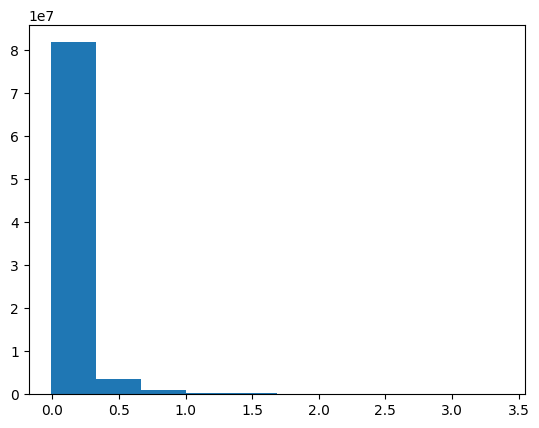

In [63]:
plt.hist(imgs[0].flatten())

In [66]:
imgs[0].shape

(166, 512, 512, 2)

In [69]:
total_n = 166 * 512 * 512 * 2

In [70]:
np.sum((imgs[0]<0.0)) / total_n

np.float64(0.010025702327130789)

In [7]:
len(slices)

450

2025-11-09 15:45:40,813 [WARNING] Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.010695458..3.3112328].


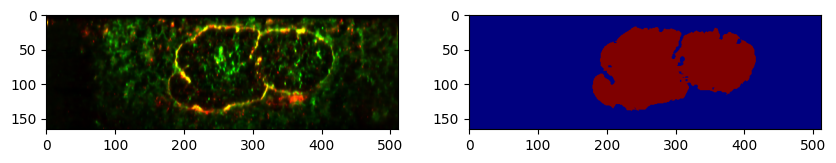

In [8]:
iidx = 317

plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.imshow(slices[iidx].transpose(1,2,0), cmap="gray") # transpose channel to be last axis for RGB plotting
plt.subplot(1,2,2)
plt.imshow(labels[iidx], cmap="jet")

In [9]:
from cellpose import train 

model = models.CellposeModel(gpu=True)

train_data = slices
train_labels = labels
# test_data = []
# test_labels = []

mpath, tloss, ttloss = train.train_seg(model.net, train_data=train_data, train_labels=train_labels,
                                        # test_data=test_data, test_labels=test_labels,
                                        nimg_per_epoch=50, min_train_masks=0,
                                        n_epochs=100, batch_size=1, learning_rate=1e-5,
                                        weight_decay=0.1, normalize=False, save_path=".", model_name=f"SMG-BM-15V")


2025-11-09 15:48:52,557 [INFO] ** TORCH CUDA version installed and working. **
2025-11-09 15:48:52,557 [INFO] >>>> using GPU (CUDA)
2025-11-09 15:48:54,016 [INFO] >>>> loading model C:\Users\wangs6\.cellpose\models\cpsam
2025-11-09 15:48:55,296 [INFO] computing flows for labels


100%|██████████| 450/450 [00:44<00:00, 10.18it/s]

2025-11-09 15:49:39,604 [INFO] >>> computing diameters



  0%|          | 0/450 [00:00<?, ?it/s]c:\Users\wangs6\AppData\Local\miniforge3\envs\cellpose\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\wangs6\AppData\Local\miniforge3\envs\cellpose\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 450/450 [00:00<00:00, 1903.83it/s]

2025-11-09 15:49:39,840 [INFO] >>> n_epochs=100, n_train=450, n_test=None
2025-11-09 15:49:39,840 [INFO] >>> AdamW, learning_rate=0.00001, weight_decay=0.10000
2025-11-09 15:49:39,840 [INFO] >>> saving model to ..\models\SMG-BM-15V


2025-11-09 15:49:46,901 [INFO] 0, train_loss=1.2536, test_loss=0.0000, LR=0.000000, time 7.06s
2025-11-09 15:50:19,315 [INFO] 5, train_loss=0.6984, test_loss=0.0000, LR=0.000006, time 39.47s
2025-11-09 15:50:51,905 [INFO] 10, train_loss=0.3560, test_loss=0.0000, LR=0.000010, time 72.06s
2025-11-09 15:51:57,714 [INFO] 20, train_loss=0.2376, test_loss=0.0000, LR=0.000010, time 137.87s
2025-11-09 15:53:03,261 [INFO] 30, train_loss=0.2310, test_loss=0.0000, LR=0.000010, time 203.42s
2025-11-09 15:54:10,042 [INFO] 40, train_loss=0.2107, test_loss=0.0000, LR=0.000010, time 270.20s
2025-11-09 15:55:15,869 [INFO] 50, train_loss=0.2110, test_loss=0.0000, LR=0.000005, time 336.03s
2025-11-09 15:56:21,534 [INFO] 60, train_loss=0.1799, test_loss=0.0000, LR=0.000001, time 401.69s
2025-11-09 15:57:27,542 [INFO] 70, train_loss=0.1713, test_loss=0.0000, LR=0.000000, time 467.70s
2025-11-09 15:58:33,612 [INFO] 80, train_loss=0.1695, test_loss=0.0000, LR=0.000000, time 533.77s
2025-11-09 15:59:39,527 [I

# run in held-out 3D datasets

In [10]:
remaining

[3, 11, 12, 13, 16]

In [11]:
model = models.CellposeModel(gpu=True, pretrained_model="models/SMG-BM-15V")

2025-11-09 16:00:45,908 [INFO] ** TORCH CUDA version installed and working. **
2025-11-09 16:00:45,909 [INFO] >>>> using GPU (CUDA)
2025-11-09 16:00:47,497 [INFO] >>>> loading model ../models/SMG-BM-15V


In [12]:
from scipy.ndimage import binary_fill_holes, label

def keep_largest_object(binary_image):
    # Label connected components
    labeled_array, num_features = label(binary_image)

    if num_features == 0:
        return np.zeros_like(binary_image)

    # Count the size of each component (excluding background)
    sizes = np.bincount(labeled_array.ravel())
    sizes[0] = 0  # Background is label 0

    # Find the label of the largest component
    largest_label = sizes.argmax()

    # Create mask for largest component only
    largest_component = labeled_array == largest_label

    return largest_component.astype(binary_image.dtype)

In [13]:
for i in remaining[:1]: # process 1 image to understand data structure of flows
    img = imgs[i]

    _masks_not_used, flows, _ = model.eval(img, normalize=False, do_3D=True, z_axis=0, channel_axis=-1,
                             cellprob_threshold=0.0, batch_size=64)

2025-11-09 16:24:23,266 [INFO] running YX: 166 planes of size (512, 512)
2025-11-09 16:25:10,063 [INFO] 100%|##########| 24/24 [00:46<00:00,  1.95s/it]
2025-11-09 16:25:10,437 [INFO] running ZY: 512 planes of size (166, 512)
2025-11-09 16:26:47,938 [INFO] 100%|##########| 52/52 [01:37<00:00,  1.88s/it]
2025-11-09 16:26:48,265 [INFO] running ZX: 512 planes of size (166, 512)
2025-11-09 16:28:29,018 [INFO] 100%|##########| 52/52 [01:40<00:00,  1.94s/it]
2025-11-09 16:28:29,579 [INFO] network run in 246.31s
2025-11-09 16:28:32,002 [INFO] masks created in 2.11s


In [17]:
type(flows[0])

numpy.ndarray

In [23]:
flows[0][5][30][10]

array([0, 0, 0], dtype=uint8)

In [24]:
masks_model_15V = []
masks_gt = []

masks_gt.append(masks[remaining[0]])

# Record results of the first test data
mask = (flows[2]>0).copy() # ignore detailed mask labels & label all cell_prob > 0 voxels as 1

mask_fill = binary_fill_holes(mask.copy(), structure=np.ones((3, 3, 3), "int"))
mask_largest = keep_largest_object(mask_fill)

masks_model_15V.append(mask_largest)

In [25]:
# process the remaining 4 testing datasets
for i in remaining[1:]:
    img = imgs[i]
    masks_gt.append(masks[i])

    _masks_not_used, flows, _ = model.eval(img, normalize=False, do_3D=True, z_axis=0, channel_axis=-1,
                             cellprob_threshold=0.0, batch_size=64)

    # Note:
    # flows[k][0] = XY(Z) flow in HSV 0-255;
    # flows[k][1] = XY(Z) flows at each pixel;
    # flows[k][2] = cell probability (if > cellprob_threshold, pixel used for dynamics);
    # flows[k][3] = final pixel locations after Euler integration;
    #
    # In this case, the dimensions of flows:
    # flows[0]: (Z, Y, X, HSV)
    # flows[1]: (XYZ_flows, Z, Y, X)
    # flows[2]: (Z, Y, X)
    #
    mask = (flows[2]>0).copy() # ignore detailed mask labels & label all cell_prob > 0 voxels as 1

    mask_fill = binary_fill_holes(mask.copy(), structure=np.ones((3, 3, 3), "int"))
    mask_largest = keep_largest_object(mask_fill)

    masks_model_15V.append(mask_largest)

2025-11-09 16:44:48,220 [INFO] running YX: 166 planes of size (512, 512)
2025-11-09 16:45:34,848 [INFO] 100%|##########| 24/24 [00:46<00:00,  1.94s/it]
2025-11-09 16:45:35,222 [INFO] running ZY: 512 planes of size (166, 512)
2025-11-09 16:47:12,742 [INFO] 100%|##########| 52/52 [01:37<00:00,  1.88s/it]
2025-11-09 16:47:13,114 [INFO] running ZX: 512 planes of size (166, 512)
2025-11-09 16:48:53,832 [INFO] 100%|##########| 52/52 [01:40<00:00,  1.94s/it]
2025-11-09 16:48:54,341 [INFO] network run in 246.12s
2025-11-09 16:48:56,551 [INFO] masks created in 1.95s
2025-11-09 16:49:01,925 [INFO] running YX: 166 planes of size (512, 512)
2025-11-09 16:49:50,972 [INFO] 100%|##########| 24/24 [00:49<00:00,  2.04s/it]
2025-11-09 16:49:51,349 [INFO] running ZY: 512 planes of size (166, 512)
2025-11-09 16:51:31,508 [INFO] 100%|##########| 52/52 [01:40<00:00,  1.93s/it]
2025-11-09 16:51:31,817 [INFO] running ZX: 512 planes of size (166, 512)
2025-11-09 16:53:13,146 [INFO] 100%|##########| 52/52 [01:4

### Re-entry point: reload saved held-out masks

Run from here to regenerate the evaluation and figures without re-running the model. The masks were written by the save cell further below (`BM-seg-benchmarking/mask_gt-k.tif`, `mask_model-k.tif`).

In [1]:
# RE-ENTRY POINT: reload the saved held-out masks so the evaluation and
# figures can be regenerated without re-running the model.
import numpy as np
import tifffile

remaining = [3, 11, 12, 13, 16]   # held-out split used for the saved masks
crops = [124, 125, 105, 105]      # same as the training cells above

masks_gt = [tifffile.imread(f"BM-seg-benchmarking/mask_gt-{k}.tif") for k in range(len(remaining))]
masks_model_15V = [tifffile.imread(f"BM-seg-benchmarking/mask_model-{k}.tif") for k in range(len(remaining))]
print([m.shape for m in masks_gt])


[(166, 512, 512), (166, 512, 512), (166, 512, 512), (166, 512, 512), (166, 512, 512)]


In [2]:
def evaluate_masks(masks_model, masks_gt):
    """
    Compute voxel-level TP, FP, FN, error rate, and average precision
    between two 3D binary masks.

    Parameters
    ----------
    masks_model : np.ndarray
        3D binary NumPy array (model predictions)
    masks_gt : np.ndarray
        3D binary NumPy array (ground truth)

    Returns
    -------
    dict
        {
            "TP": int,
            "FP": int,
            "FN": int,
            "error_rate": float,
            "average_precision": float
        }
    """
    # Ensure binary and same shape
    assert masks_model.shape == masks_gt.shape, "Arrays must have the same shape"
    masks_model = (masks_model > 0).astype(np.uint8)
    masks_gt = (masks_gt > 0).astype(np.uint8)

    # Calculate TP, FP, FN
    TP = np.sum((masks_model == 1) & (masks_gt == 1))
    FP = np.sum((masks_model == 1) & (masks_gt == 0))
    FN = np.sum((masks_model == 0) & (masks_gt == 1))

    # Avoid division by zero
    denominator_error = (TP + FN) if (TP + FN) > 0 else np.nan
    denominator_precision = (TP + FN + FP) if (TP + FN + FP) > 0 else np.nan

    error_rate = (FP + FN) / denominator_error
    # NOTE: TP / (TP + FP + FN) is the voxel-level IoU (Jaccard index), following
    # cellpose's object-level 'average precision' convention. True precision
    # would be TP / (TP + FP).
    average_precision = TP / denominator_precision

    return {
        "TP": int(TP),
        "FP": int(FP),
        "FN": int(FN),
        "error_rate": error_rate,
        "average_precision": average_precision
    }

In [3]:
for i, ii in enumerate(remaining):
    print(i, ii)

0 3
1 11
2 12
3 13
4 16


In [4]:
# Note that the y_crop_start was because of the algorithm-processed segementation
# and the annotations didn't include the base part of the primary duct
# One crop value per block of 5 volumes, matching crops[i//5] used for training.
y_crop_start = np.repeat(crops, 5)   # [124]*5 + [125]*5 + [105]*5 + [105]*5
voxel_stats = []
for i, ii in enumerate(remaining):
    y_start = y_crop_start[ii]
    voxel_stats.append(evaluate_masks(masks_model_15V[i][:, y_start:, :], masks_gt[i][:, y_start:, :]))

error_rates = [voxel_stats[i]['error_rate'] for i in range(len(voxel_stats))]
average_precisions = [voxel_stats[i]['average_precision'] for i in range(len(voxel_stats))]

print("Error rates:", error_rates)
print("Average precisions:", average_precisions)

Error rates: [np.float64(0.029323386445440896), np.float64(0.024421034941989925), np.float64(0.024429590628781746), np.float64(0.02572121349643517), np.float64(0.034258902309414224)]
Average precisions: [np.float64(0.9712089153520397), np.float64(0.975995659564553), np.float64(0.9759775535131131), np.float64(0.9747156164970782), np.float64(0.9664532060286206)]


In [5]:
# sample sd (ddof=1), matching seaborn's errorbar='sd' (pandas .std())
np.mean(error_rates), np.std(error_rates, ddof=1)

(np.float64(0.027630825564412393), np.float64(0.004212880335254007))

In [6]:
# sample sd (ddof=1), matching seaborn's errorbar='sd' (pandas .std())
np.mean(average_precisions), np.std(average_precisions, ddof=1)

(np.float64(0.9728701901910808), np.float64(0.004085565557624414))

In [7]:
error_rates + average_precisions

[np.float64(0.029323386445440896),
 np.float64(0.024421034941989925),
 np.float64(0.024429590628781746),
 np.float64(0.02572121349643517),
 np.float64(0.034258902309414224),
 np.float64(0.9712089153520397),
 np.float64(0.975995659564553),
 np.float64(0.9759775535131131),
 np.float64(0.9747156164970782),
 np.float64(0.9664532060286206)]

In [8]:
import pandas as pd

df = pd.DataFrame({'categories': ['Error rate']*5 + ['IoU']*5,
                   'values': error_rates + average_precisions})

In [9]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# plotting configuration
font = {'family' : 'Arial',
        'size'   : 8}
matplotlib.rc('font', **font)
plt.rcParams['svg.fonttype'] = 'none'

In [10]:
import os

In [11]:

# Make a folder if it is not already there to store figures 
os.makedirs('jupyter_figures', exist_ok=True)

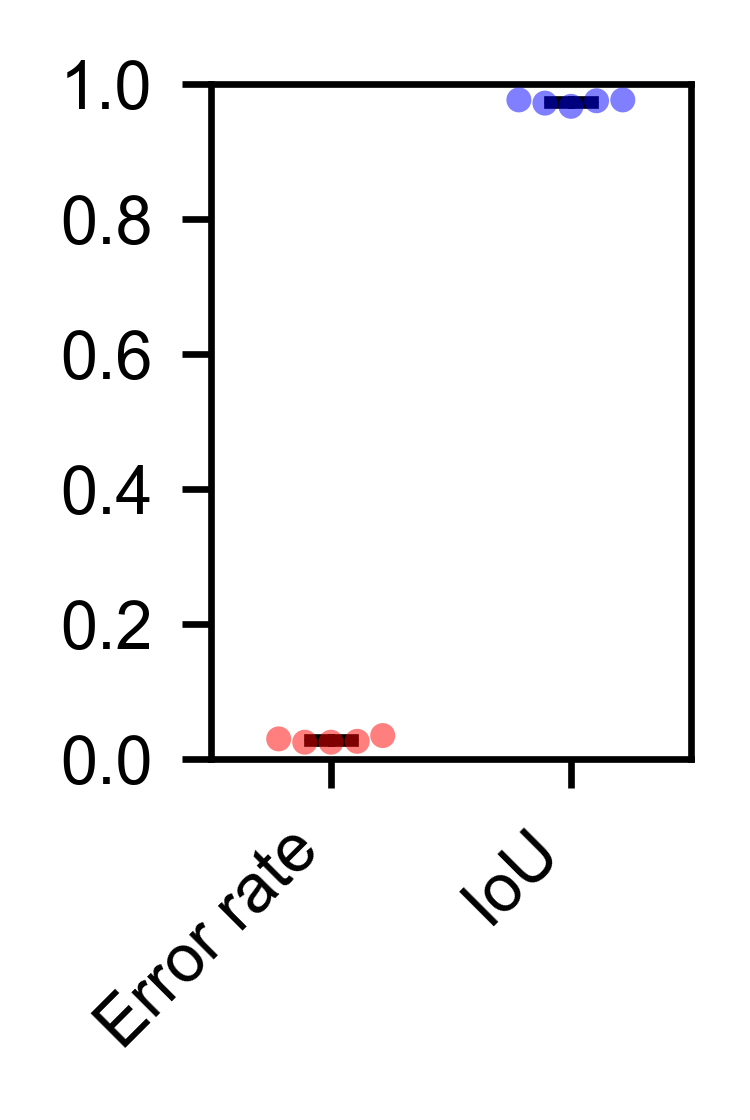

In [12]:
outputPrefix = 'BM_seg_model_benchmarking'
outputFigPath = "jupyter_figures/" + outputPrefix + ".svg"
# outputFigPath = "jupyter_figures/" + outputPrefix + ".png"

plotting_order = ['Error rate', 'IoU']

fig_width=1
fig_height=1.5
fig = plt.figure(figsize=(fig_width,fig_height), dpi=600)
ax = fig.add_axes([0.15, 0.2, 0.8, 0.75])


ax = sns.swarmplot(data = df,  x = 'categories', y = 'values',
                   order = plotting_order,
                   hue = 'categories',
                   palette=["red", "blue"],
                #    color="blue",
                   size=3,
                   alpha=0.5)


ax = sns.pointplot(data = df, x = 'categories', y = 'values',
                   markers='_',
                   markersize=3,
                   linewidth=0.8,
                   color="k",
                   alpha=1.0,
                   order = plotting_order,
                #    errwidth=0.8,
                   errorbar='sd',
                   capsize=.2,
                   linestyles="none"
                   )

plt.ylim(0.0, 1.0)
# plt.yticks([0, 1, 2, 3, 4])

plt.xlabel(None)
plt.ylabel(None)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(labels=ax.get_xticklabels(), rotation=45, ha="right")

for o in fig.findobj():
    o.set_clip_on(False)
for o in ax.findobj():
    o.set_clip_on(False)

if outputFigPath is not None:
    plt.savefig(outputFigPath)


In [13]:
def change_bar_width(ax, new_value):
    '''modify the bar width in bar plots
    
    Input Parameters:
    -----------------
        ax: a matplotlib axis object
        new_value: the desired bar width
    
    Returns:
    --------
        ax: modified axis object
    
    '''
    for patch in ax.patches :
        current_width = patch.get_width()
        diff = current_width - new_value

        # we change the bar width
        patch.set_width(new_value)

        # we recenter the bar
        patch.set_x(patch.get_x() + diff * .5)
        
    return ax


def change_bar_height(ax, new_value):
    '''modify the bar height in horizontal bar plots

    Input Parameters:
    -----------------
        ax: a matplotlib axis object
        new_value: the desired bar height

    Returns:
    --------
        ax: modified axis object

    '''
    for patch in ax.patches :
        current_height = patch.get_height()
        diff = current_height - new_value

        # we change the bar height
        patch.set_height(new_value)

        # we recenter the bar
        patch.set_y(patch.get_y() + diff * .5)

    return ax


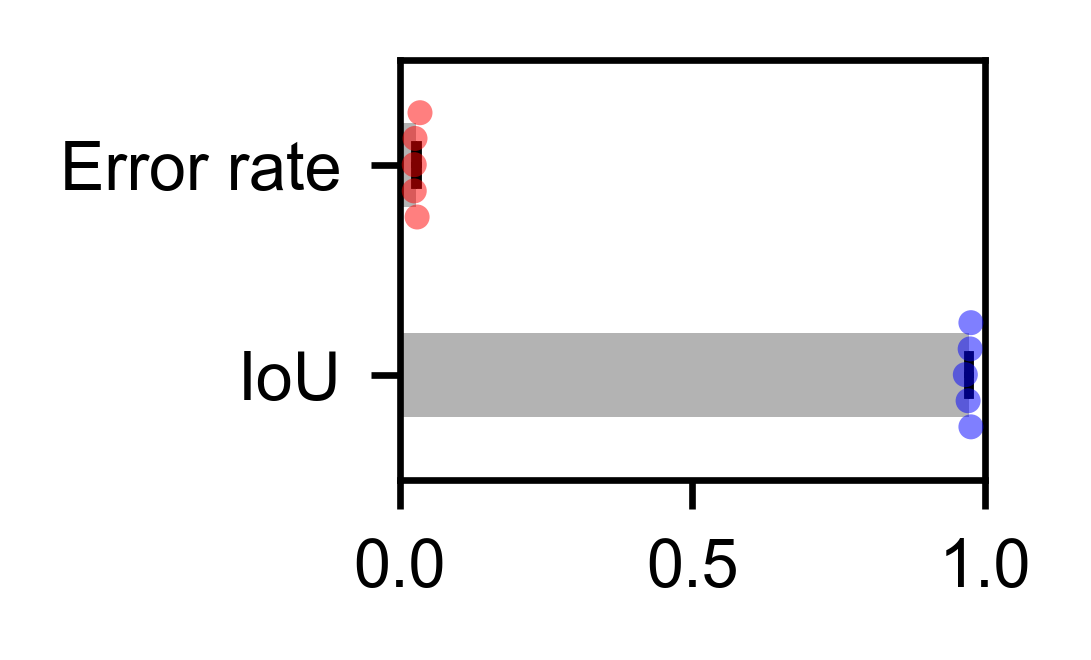

In [14]:
outputPrefix = 'BM_seg_model_benchmarking'
outputFigPath = "jupyter_figures/" + outputPrefix + "-bar.svg"
# outputFigPath = "jupyter_figures/" + outputPrefix + ".png"

plotting_order = ['Error rate', 'IoU']

# horizontal layout: values on x, categories on y
fig_width=1.5
fig_height=1
fig = plt.figure(figsize=(fig_width,fig_height), dpi=600)
ax = fig.add_axes([0.3, 0.25, 0.65, 0.7])

ax = sns.barplot(data = df, x = 'values', y = 'categories',
                 orient='h',
                 color=".7", alpha=1.0,
                 order = plotting_order,
                 errorbar='sd',   # seaborn uses the sample sd (ddof=1)
                 err_kws={'linewidth': 0.7, 'color': 'k'},
                 capsize=.2)

ax = sns.swarmplot(data = df,  x = 'values', y = 'categories',
                   orient='h',
                   order = plotting_order,
                   hue = 'categories',
                   palette=["red", "blue"],
                #    color="blue",
                   size=3,
                   alpha=0.5,
                   legend=False)


plt.xlim(0.0, 1.0)
plt.xticks([0.0, 0.5, 1.0])

plt.xlabel(None)
plt.ylabel(None)

change_bar_height(ax, 0.4)

for o in fig.findobj():
    o.set_clip_on(False)
for o in ax.findobj():
    o.set_clip_on(False)

if outputFigPath is not None:
    plt.savefig(outputFigPath)


In [41]:
imgs[0].dtype

dtype('float32')

In [46]:
imgs[remaining[0]].max()

np.float32(3.512928)

In [ ]:
for i in range(len(masks_gt)):
    # save original image
    # imgs are percentile-normalized floats (range ~ -0.01 .. 3.5), so
    # (img * 65535).astype("uint16") overflows/wraps. Clip negatives and
    # rescale by the volume max before converting.
    img_out = np.clip(imgs[remaining[i]], 0, None)
    img_out = (img_out / img_out.max() * 65535).astype("uint16")
    io.imsave( "BM-seg-benchmarking/raw-"+str(i)+".tif", img_out)
    io.imsave( "BM-seg-benchmarking/mask_gt-"+str(i)+".tif", masks_gt[i].astype("uint8"))
    io.imsave( "BM-seg-benchmarking/mask_model-"+str(i)+".tif", masks_model_15V[i].astype("uint8"))

2025-07-20 15:36:13,015 [WARNING] Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008328726..2.2897522].


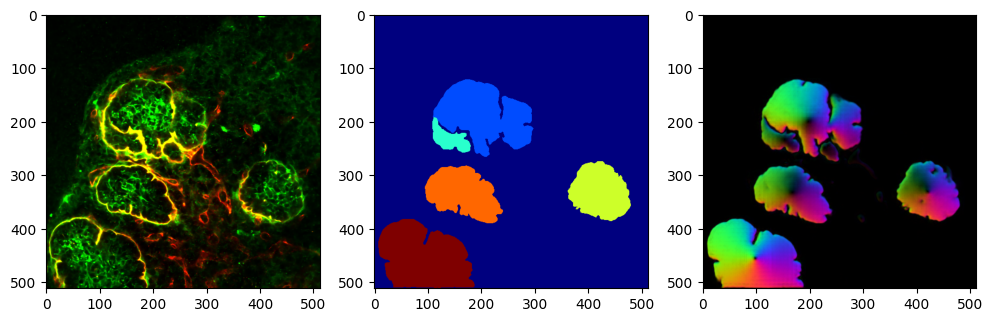

In [26]:
img_2d = img[60].copy()
mask_2d, flows_2d, _ = model.eval(img_2d, diameter=30)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(np.concatenate((img_2d, img_2d[:,:,:1]*0), axis=-1), cmap="gray", vmin=0, vmax=1)
ax[1].imshow(mask_2d, cmap="jet", vmin=0, vmax=mask_2d.max())
ax[2].imshow(flows_2d[0])

2025-07-20 15:39:15,580 [WARNING] Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008328726..2.2897522].


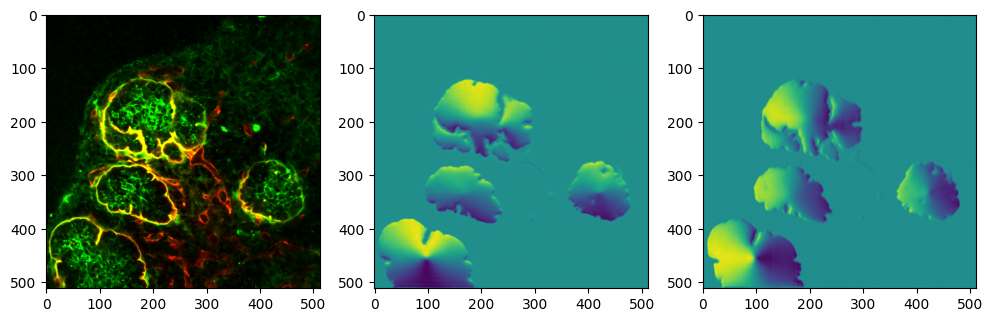

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(np.concatenate((img_2d, img_2d[:,:,:1]*0), axis=-1), cmap="gray", vmin=0, vmax=1)
ax[1].imshow(flows_2d[1][0])
ax[2].imshow(flows_2d[1][1])